# Pokémon Wordle: Intelligent Guessing Strategies

## Main Project Notebook

**Project:** Pokémon Wordle AI  
**Dataset:** Pokémon dataset containing 386 records  
**Algorithms:** Random, Filter, Entropy and Minimax  
**Maximum guesses per game:** 8

This notebook documents the dataset, game mechanics, solver integration, experimental evaluation and findings.


## 1. Project Objectives

- Implement a Pokémon attribute-based guessing game.
- Apply four different guessing strategies.
- Evaluate their performance using a common 8-guess limit.
- Compare accuracy, average guesses and computational time.
- Identify the most effective strategy based on experimental results.


## 2. Environment Setup

Import the existing project modules. The implementation is maintained in separate Python files to support modularity and reuse.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os
import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/pokemon_wordle"
os.chdir(PROJECT_DIR)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from loader import load_pokemon
from engine import Game, feedback, MAX_GUESSES, FAIL_SCORE
from basic_solvers import random_solver, filter_solver, filter_candidates
from entropy_solver import EntropySolver
from minimax_solver import MinimaxSolver
from benchmark import run_all

print("Project directory:", PROJECT_DIR)
print("Maximum guesses:", MAX_GUESSES)


Project directory: /content/drive/MyDrive/pokemon_wordle
Maximum guesses: 8


## 3. Dataset Loading and Exploration

The project dataset contains Pokémon attributes used by the game:

- Name
- Generation
- Primary type
- Secondary type
- Height
- Weight

The loader module handles reading and preparing the dataset.


In [6]:
pokemon = load_pokemon(os.path.join(PROJECT_DIR, "data", "pokemon.csv"))

dataset = pd.DataFrame(pokemon)

print("Dataset shape:", dataset.shape)
print("\nDataset columns:")
print(dataset.columns.tolist())

display(dataset.head(10))


Dataset shape: (386, 6)

Dataset columns:
['name', 'gen', 'type1', 'type2', 'height', 'weight']


,name,gen,type1,type2,height,weight
0,Bulbasaur,1,Grass,Poison,0.7,6.9
1,Ivysaur,1,Grass,Poison,1.0,13.0
2,Venusaur,1,Grass,Poison,2.0,100.0
3,Charmander,1,Fire,None,0.6,8.5
4,Charmeleon,1,Fire,None,1.1,19.0
5,Charizard,1,Fire,Flying,1.7,90.5
6,Squirtle,1,Water,None,0.5,9.0
7,Wartortle,1,Water,None,1.0,22.5
8,Blastoise,1,Water,None,1.6,85.5
9,Caterpie,1,Bug,None,0.3,2.9


In [7]:
print("Dataset information:")
display(dataset.describe(include="all"))

print("\nMissing values:")
display(dataset.isnull().sum())

print("\nPokémon per generation:")
display(dataset["gen"].value_counts().sort_index())


Dataset information:


,name,gen,type1,type2,height,weight
count,386,386.000000,386,386,386.000000,386.000000
unique,386,NaN,17,18,NaN,NaN
top,Bulbasaur,NaN,Water,None,NaN,NaN
freq,1,NaN,70,204,NaN,NaN
mean,NaN,1.958549,NaN,NaN,1.198705,54.157254
std,NaN,0.860892,NaN,NaN,1.193325,84.442770
min,NaN,1.000000,NaN,NaN,0.200000,0.100000
25%,NaN,1.000000,NaN,NaN,0.600000,9.925000
50%,NaN,2.000000,NaN,NaN,1.000000,29.250000
75%,NaN,3.000000,NaN,NaN,1.500000,60.000000



Missing values:


,0
name,0
gen,0
type1,0
type2,0
height,0
weight,0



Pokémon per generation:


,count
gen,
1,151
2,100
3,135


## 4. Game Mechanics and Feedback System

The game compares a guessed Pokémon with the secret Pokémon using five attributes:

1. Generation
2. Type 1
3. Type 2
4. Height
5. Weight

Feedback meanings:

- Green: exact match or within the defined numerical tolerance.
- Amber: a type is present in the other type slot.
- Grey: type does not match.
- Up / Down: the answer has a higher or lower numerical value.

Height and weight use a 10% tolerance band. The game ends when the correct Pokémon is guessed or the maximum number of guesses is reached.


In [8]:
# Demonstrate the feedback function using two dataset records
guess = pokemon[0]
answer = pokemon[1]

print("Guess:", guess["name"])
print("Answer:", answer["name"])
print("Feedback:", feedback(guess, answer))


Guess: Bulbasaur
Answer: Ivysaur
Feedback: ('green', 'green', 'green', 'up', 'up')


## 5. Implemented Guessing Strategies

The project integrates four strategies:

**Random:** Selects an unguessed Pokémon without using previous clues.

**Filter:** Removes Pokémon inconsistent with the feedback received and selects from the remaining candidates.

**Entropy:** Uses information theory to select guesses intended to reduce uncertainty.

**Minimax:** Selects guesses by minimizing the worst-case remaining candidate set.

The implementations are maintained in `basic_solvers.py`, `entropy_solver.py` and `minimax_solver.py`.


In [9]:
print("Basic solvers:", random_solver.__name__, filter_solver.__name__)

entropy = EntropySolver(pokemon=pokemon)
minimax = MinimaxSolver()

print("Entropy solver initialized:", type(entropy).__name__)
print("Minimax solver initialized:", type(minimax).__name__)


Basic solvers: random_solver filter_solver
Entropy solver initialized: EntropySolver
Minimax solver initialized: MinimaxSolver


## 6. Experimental Methodology

All algorithms are evaluated with a maximum of 8 guesses.

- Dataset size: 386 Pokémon.
- Random: 5 runs per possible secret.
- Filter: 5 runs per possible secret.
- Entropy: 1 run per possible secret.
- Minimax: 1 run per possible secret.

Random and Filter use stochastic selection, while Entropy and Minimax are deterministic in this implementation.

A failed game uses all 8 available attempts. Win rate is calculated as the percentage of games solved within the limit.


## 7. Benchmark Results

The following cell loads the verified benchmark output generated by `benchmark.py`.


In [10]:
results_path = os.path.join(PROJECT_DIR, "results", "results_table.csv")
results = pd.read_csv(results_path)

display(results)

assert results["Worst case"].max() <= MAX_GUESSES
assert "Win rate (%)" in results.columns

print("Benchmark validation passed.")


,Solver,Runs,Avg guesses,Median,Worst case,Win rate (%),Solved in <=6 (%),ms per game
0,Random,1930,7.91,8.0,8,2.33,1.87,0.41
1,Filter,1930,3.75,4.0,8,100.00,98.45,1.86
2,Entropy,386,3.07,3.0,5,100.00,100.00,9.47
3,Minimax,386,3.14,3.0,5,100.00,100.00,9.44


Benchmark validation passed.


## 8. Performance Visualization

The following charts compare average guesses and win rates across the four strategies.


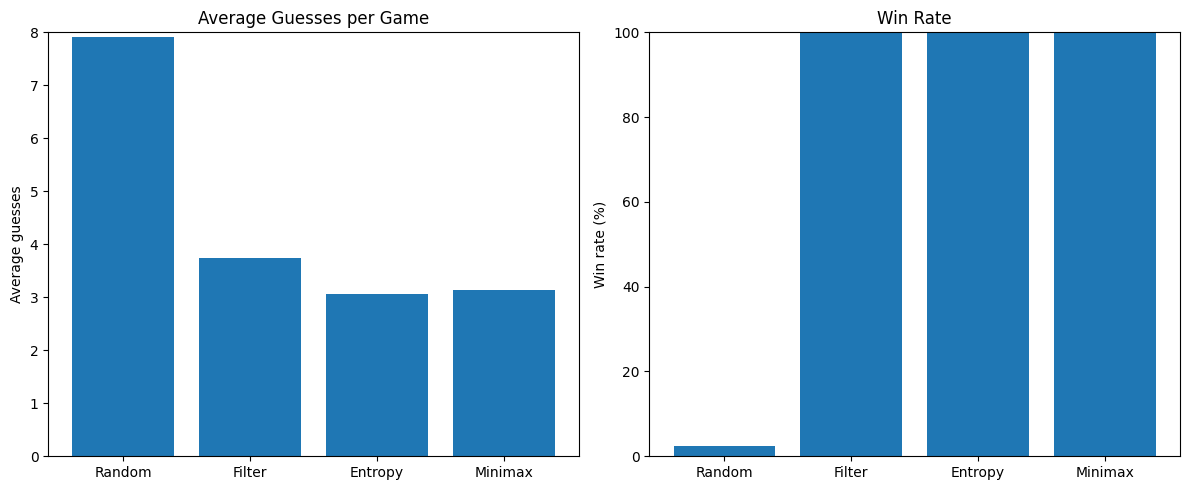

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(results["Solver"], results["Avg guesses"])
axes[0].set_title("Average Guesses per Game")
axes[0].set_ylabel("Average guesses")
axes[0].set_ylim(0, MAX_GUESSES)

axes[1].bar(results["Solver"], results["Win rate (%)"])
axes[1].set_title("Win Rate")
axes[1].set_ylabel("Win rate (%)")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()


## 9. Experimental Findings

The verified benchmark produced the following results:

| Algorithm | Average guesses | Win rate |
|---|---:|---:|
| Random | 7.91 | 2.33% |
| Filter | 3.75 | 100% |
| Entropy | 3.07 | 100% |
| Minimax | 3.14 | 100% |

Entropy achieved the lowest average guesses among the evaluated algorithms. Minimax also achieved a 100% win rate, with a slightly higher average number of guesses.

Filter achieved a 100% win rate, demonstrating the effectiveness of eliminating candidates using feedback.

Random performed poorly because it does not use the information provided by previous guesses.


## 10. Conclusion

The experimental evaluation demonstrates that informed guessing strategies substantially outperform random guessing in Pokémon Wordle.

Entropy achieved the lowest average number of guesses, while Minimax provided comparable performance. The Filter strategy also solved every tested game within the 8-guess limit.

The findings highlight the importance of using feedback and candidate reduction when designing intelligent guessing systems.

## 11. Project Files

The project is organized into separate modules:

- `engine.py` — game rules and feedback.
- `loader.py` — dataset loading.
- `basic_solvers.py` — Random and Filter strategies.
- `entropy_solver.py` — Entropy strategy.
- `minimax_solver.py` — Minimax strategy.
- `benchmark.py` — experimental evaluation.
- `app.py` — Streamlit application.
- `data/pokemon.csv` — primary dataset.
- `results/` — benchmark output files.

**Note:** Benchmark results represent the current implementation and evaluation settings. Timing measurements may vary between runs and hardware environments.
